# Conformal Pillbox Geometry – Visual Check

Dieses Notebook lädt die vorhandene WAKIS-Pillbox-Geometrie und ergänzt ein drittes STL-Volumen im oberen Bereich der Cavity.

- `cavity`: Vakuum (`normal`)
- `shell`: PEC
- `dielectric`: $\varepsilon_r=4$, `normal`

Damit enthält ein zentraler Querschnitt sowohl **normal–PEC**- als auch **normal–normal**-Übergänge. Anschließend wird die neue Conformal-Edge-Slice-Plotfunktion aufgerufen.


In [1]:
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import pyvista as pv

from wakis import GridFIT3D, SolverFIT3D

## Repository und Standard-Pillbox-STLs

Das Notebook sucht automatisch den WAKIS-Repository-Root und verwendet die bereits vorhandenen Test-STLs.


In [2]:
cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

cavity_mesh = pv.read(cavity_path).triangulate().clean()
shell_mesh = pv.read(shell_path).triangulate().clean()

## Zusätzliches Dielektrik-Volumen

Der Block liegt vollständig im oberen/zentralen Bereich der Cavity. Dadurch vermeiden wir für diesen ersten Visualisierungstest unnötige koinzidente Flächen mit der PEC-Shell.


In [3]:
xmin, xmax, ymin, ymax, zmin, zmax = cavity_mesh.bounds

dielectric_bounds = (
    xmin + 0.25 * (xmax - xmin),
    xmax - 0.25 * (xmax - xmin),
    0.5 * (ymin + ymax),
    ymin + 0.72 * (ymax - ymin),
    zmin + 0.15 * (zmax - zmin),
    zmax - 0.15 * (zmax - zmin),
)

dielectric_mesh = pv.Box(bounds=dielectric_bounds).triangulate()

dielectric_path = Path("pillbox_upper_dielectric.stl")
dielectric_mesh.save(dielectric_path)

## Conformal Grid und Solver

Wichtig ist die Reihenfolge der Solids: `dielectric` steht zuletzt und hat damit in seinem Volumen Priorität gegenüber der überlappenden `cavity`-Region.


In [4]:
stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
    "dielectric": str(dielectric_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
    "dielectric": [4.0, 1.0, 0.0],
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
    "dielectric": "normal",
}

all_geometry = cavity_mesh + shell_mesh
xmin, xmax, ymin, ymax, zmin, zmax = all_geometry.bounds

# Moderate resolution: coarse enough to clearly see individual clipped edges.
Nx, Ny, Nz = 30, 30, 60

grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    geometry_mode="conformal",
    stl_method="interior_points",
    verbose=1,
)

solver = SolverFIT3D(
    grid,
    bg=[1.0, 1.0, 0.0],
    use_stl=True,
    verbose=1,
)

Generating grid with 54000 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 12939 primal points, 12322 cell centers, and 12759 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 6593 primal points, 5243 cell centers, and 6902 dual points marked inside the solid.
 * Marking grid points inside STL solid 'dielectric'...
    * STL solid dielectric: 2954 primal points, 2380 cell centers, and 3528 dual points marked inside the solid.
    * primal x-edges: 4466 geometric hits, 4466 crossings, 0 contacts, 886 with multiple crossing positions
    * primal y-edges: 5036 geometric hits, 5036 crossings, 0 contacts, 976 with multiple crossing positions
    * primal z-edges: 2590 geometric hits, 2590 crossings, 0 contacts, 862 with multiple crossing positions
    * dual x-edges: 4259 geometric hits, 4259 crossings, 0 contacts, 865 with multiple crossing positions
    * dual y-

D:\Wakis\WAKIS\wakis\gridFIT3D.py:3580: UserWarning: Conformal geometry diagnostics:
948 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
2104 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
5351 edges contain multiple crossing positions. 4985 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
17 edges cross the same STL at more than one distinct position. The geometry on these edges is not fully resolved by the current single-crossing treatment.
  dual x-edge (14, 11, 12): cavity, shell
  dual x-edge (14, 11, 47): cavity, shell
  dual x-edge (14, 18, 12): cavity, shell
  dual x-edge (14, 18, 47): cavity, shell
  dual x-edge (14, 20, 13): shell
  ... and 12 more.
  self._warn_interface_diagnostics()


    * primal x-faces: 6840 candidates, 4591 segments, 1365 resolved splits
    * primal y-faces: 6431 candidates, 4479 segments, 3079 resolved splits
    * primal z-faces: 8684 candidates, 6480 segments, 3230 resolved splits
    * dual x-faces: 6821 candidates, 4988 segments, 1367 resolved splits
    * dual y-faces: 6150 candidates, 4373 segments, 2988 resolved splits
    * dual z-faces: 8492 candidates, 6733 segments, 3686 resolved splits
Total grid initialization time: 11.143930435180664 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Total solver initialization time: 4.383815288543701 s


## Conformal Edge Slice

Der mittlere `z`-Slice zeigt die x-y-Ebene der Pillbox. Dort sollten sichtbar sein:

- außen die gekürzten Kanten an der PEC-Shell,
- innen vollständige Vakuum-Kanten,
- im oberen Bereich die Vakuum–Dielektrikum-Grenze,
- die tatsächlichen STL-Schnittlinien als dünne Referenz.


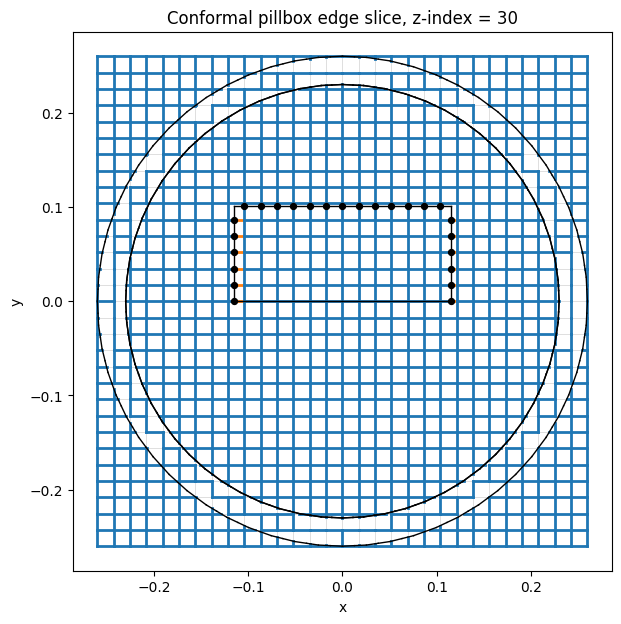

In [5]:
slice_index = Nz // 2

ax = solver.plot_conformal_primal_edge_slice(
    normal="z",
    index=slice_index,
    show_full_grid=True,
    show_stl=True,
    show_intersection_marker=True,
    split_normal_normal=True,
)

ax.set_title(f"Conformal pillbox edge slice, z-index = {slice_index}")
plt.show()

## Optional: anderer Querschnitt

Falls du anschließend die Geometrie aus einer zweiten Richtung prüfen willst, kannst du z. B. einen mittleren `y`-Slice verwenden.


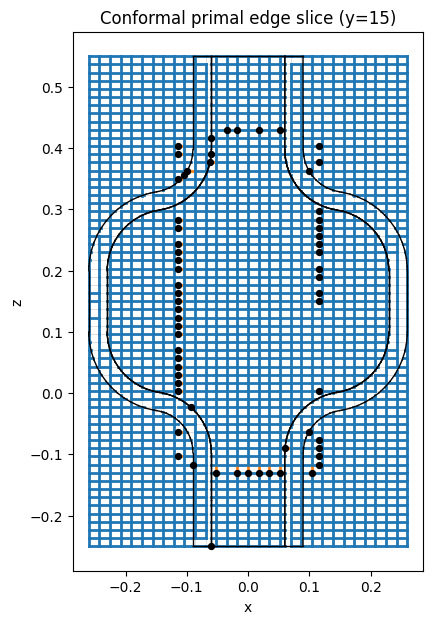

In [6]:
# Optional
ax = solver.plot_conformal_primal_edge_slice(
    normal="y",
    index=Ny // 2,
    show_full_grid=True,
    show_stl=True,
    show_intersection_marker=True,
    split_normal_normal=True,
)
plt.show()